# Compact Convolutional Transformers on BigEarthNet-19 — corrected benchmark

A re-run of my 2024 capstone ("Benchmarking Compact Convolutional Transformers using the BigEarthNet Dataset").
The original reported micro-F1 ≈ 0.18 for CCT-2 / CCT-4. This notebook shows that number was produced by the
evaluation code, not by the model, and re-does the benchmark with a pipeline that can be trusted.

**What was wrong in the original**

| # | Problem | Effect |
|---|---|---|
| 1 | Test set was built with `shuffle=True`, then `model.predict()` output was scored against `ds["test"]["labels"]` in the *original* order | Precision / recall / F1 were computed between predictions and the labels of **different images**. Per-class precision equals class frequency (r = 0.999) — the signature of chance-level scoring. |
| 2 | "Accuracy" was Keras `CategoricalAccuracy` (does the arg-max logit land on a positive label?) | Not a multi-label metric, and not the quantity the benchmark paper calls accuracy (which is micro-Jaccard, TP / (TP+FP+FN)). It was also the checkpoint-selection metric. |
| 3 | `RandomCrop(32, 32)` on 120×120 multi-label patches | The model saw 7% of each patch while being asked for the labels of the whole patch. |
| 4 | PNGs decoded in Python on every step; 900-token sequences for 120×120 input | ~5 h / epoch, which is what forced the 32-px crop and the 4-epoch run. |
| 5 | Stray quote in the checkpoint path (`"'/content/drive/...`) | "Best" weights were never reloaded; Experiment 2's notebook evaluated weights from an interrupted first epoch. |
| 6 | Label smoothing 0.1 on a 19-way multi-label BCE, constant learning rate, no warm-up | Smaller effects, all in the wrong direction. |

**What this notebook does instead**

1. Decodes the dataset **once** into a `uint8` array on local disk (and onto the GPU if it fits), so an epoch takes minutes.
2. Trains CCT on the **full 120×120 patch** with a tokenizer sized for that resolution (225 tokens instead of 900).
3. Uses label-preserving augmentation only (flips and 90° rotations).
4. Evaluates in a single un-shuffled pass where predictions and labels come out of the same loop, with real multi-label metrics.
5. Reproduces the original bug on purpose (section 9) so the diagnosis is checkable.

**How to run:** Colab → Runtime → GPU (A100 or L4 preferred, T4 works) → *Run all*. Change `MODEL` in the config cell to
train `cct2`, `cct4`, `cct7` or the `resnet18` baseline; each run writes to its own folder and the last section tabulates all of them.

In [1]:
# ------------------------------- configuration -------------------------------
import os

MODEL       = "cct7"      # "cct2" | "cct4" | "cct7" | "resnet18" (same-pipeline CNN baseline)
EPOCHS      = 30          # the benchmark paper trains for 30
BATCH_SIZE  = 256
PEAK_LR     = 6e-4        # reached after WARMUP_EPOCHS, then cosine decay to ~0 (CCT paper uses ~5.5e-4)
WARMUP_EPOCHS = 2
WEIGHT_DECAY  = 0.05
DROP_PATH   = 0.1         # stochastic depth (CCT only)
SEED        = 0

DATA_SOURCE = "hf"        # "hf" = danielz01/BigEarthNet-S2-v1.0, "synthetic" = tiny fake data for a wiring test
DATA_ON_GPU = "auto"      # keep the uint8 training set on the GPU when it fits (fastest); True / False / "auto"
USE_DRIVE   = True        # save checkpoints + results to Google Drive so a disconnect does not lose the run

CACHE_DIR   = "/content/ben19_cache"                 # decoded uint8 arrays (~22 GB, local disk, rebuilt in minutes)
OUT_ROOT    = "/content/drive/MyDrive/cct_bigearthnet_v2" if USE_DRIVE else "/content/cct_bigearthnet_v2"

# Smoke-test overrides (used to check the notebook end-to-end on CPU; leave unset for real runs)
if os.environ.get("BEN_SMOKE"):
    DATA_SOURCE, USE_DRIVE, DATA_ON_GPU = "synthetic", False, False
    EPOCHS = int(os.environ.get("BEN_EPOCHS", 2)); BATCH_SIZE = 32; WARMUP_EPOCHS = 1
    MODEL = os.environ.get("BEN_MODEL", MODEL)
    CACHE_DIR = os.environ["BEN_SMOKE"] + "/cache"; OUT_ROOT = os.environ["BEN_SMOKE"] + "/out"

RUN_DIR = f"{OUT_ROOT}/{MODEL}"

In [2]:
# ------------------------------- setup -------------------------------
import json, math, time, random, glob
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except ImportError:
        print("Not running in Colab - writing to", OUT_ROOT)
os.makedirs(RUN_DIR, exist_ok=True); os.makedirs(CACHE_DIR, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    torch.backends.cudnn.benchmark = True
    torch.set_float32_matmul_precision("high")
    print(torch.cuda.get_device_name(0), f"| {torch.cuda.mem_get_info()[0]/2**30:.1f} GB free")
else:
    print("WARNING: no GPU - fine for the synthetic wiring test, far too slow for the real dataset.")
print("run dir:", RUN_DIR)

Mounted at /content/drive
NVIDIA A100-SXM4-80GB | 78.8 GB free
run dir: /content/drive/MyDrive/cct_bigearthnet_v2/cct7


## 1. Labels: 43 CORINE classes → BigEarthNet-19
Same mapping as the original project. Eleven of the 43 classes are dropped; patches left with no label are excluded.

In [3]:
CLASSES = [
    "Urban fabric", "Industrial or commercial units", "Arable land", "Permanent crops", "Pastures",
    "Complex cultivation patterns",
    "Land principally occupied by agriculture, with significant areas of natural vegetation",
    "Agro-forestry areas", "Broad-leaved forest", "Coniferous forest", "Mixed forest",
    "Natural grassland and sparsely vegetated areas", "Moors, heathland and sclerophyllous vegetation",
    "Transitional woodland, shrub", "Beaches, dunes, sands", "Inland wetlands", "Coastal wetlands",
    "Inland waters", "Marine waters",
]
SHORT = ["Urban fabric", "Industrial/commercial", "Arable land", "Permanent crops", "Pastures", "Complex cultivation",
         "Agriculture + natural veg.", "Agro-forestry", "Broad-leaved forest", "Coniferous forest", "Mixed forest",
         "Natural grassland/sparse", "Moors/heath/sclerophyllous", "Transitional woodland/shrub", "Beaches/dunes/sands",
         "Inland wetlands", "Coastal wetlands", "Inland waters", "Marine waters"]
NUM_CLASSES = len(CLASSES)
CLASS_IDX = {c: i for i, c in enumerate(CLASSES)}

MERGE = {
    "Continuous urban fabric": "Urban fabric", "Discontinuous urban fabric": "Urban fabric",
    "Non-irrigated arable land": "Arable land", "Permanently irrigated land": "Arable land", "Rice fields": "Arable land",
    "Vineyards": "Permanent crops", "Fruit trees and berry plantations": "Permanent crops",
    "Olive groves": "Permanent crops", "Annual crops associated with permanent crops": "Permanent crops",
    "Natural grassland": "Natural grassland and sparsely vegetated areas",
    "Sparsely vegetated areas": "Natural grassland and sparsely vegetated areas",
    "Moors and heathland": "Moors, heathland and sclerophyllous vegetation",
    "Sclerophyllous vegetation": "Moors, heathland and sclerophyllous vegetation",
    "Inland marshes": "Inland wetlands", "Peatbogs": "Inland wetlands",
    "Salt marshes": "Coastal wetlands", "Salines": "Coastal wetlands",
    "Water courses": "Inland waters", "Water bodies": "Inland waters",
    "Coastal lagoons": "Marine waters", "Estuaries": "Marine waters", "Sea and ocean": "Marine waters",
    "Transitional woodland/shrub": "Transitional woodland, shrub",
}
DROPPED = {"Road and rail networks and associated land", "Sport and leisure facilities", "Port areas", "Airports",
           "Mineral extraction sites", "Dump sites", "Construction sites", "Green urban areas", "Bare rock",
           "Burnt areas", "Intertidal flats"}

def to_multi_hot(labels43):
    y = np.zeros(NUM_CLASSES, np.uint8)
    for name in labels43:
        if name in DROPPED:
            continue
        name = MERGE.get(name, name)
        if name not in CLASS_IDX:
            raise KeyError(f"Unexpected label in dataset: {name!r}")   # fail loudly rather than silently mislabel
        y[CLASS_IDX[name]] = 1
    return y

assert to_multi_hot(["Rice fields", "Airports", "Sea and ocean", "Estuaries"]).tolist() == \
       [0, 0, 1] + [0] * 15 + [1]

In [11]:
from google.colab import userdata
from huggingface_hub import login
hf_token = userdata.get('HF_TOKEN')
login(token=hf_token)

## 2. Decode the dataset once
The original pipeline decoded every PNG in Python on every step. Here each split is decoded a single time into a
`uint8` array of shape `(N, 120, 120, 3)` on local disk (train ≈ 11.6 GB, all three splits ≈ 22 GB). Later runs reuse it.

In [12]:
SPLITS = ["train", "val", "test"]
IMG = 120

def build_cache_hf(split):
    from datasets import load_dataset
    from tqdm.auto import tqdm
    ds = load_dataset("danielz01/BigEarthNet-S2-v1.0", split=split).select_columns(["img", "labels"])
    n = len(ds)
    X = np.lib.format.open_memmap(f"{CACHE_DIR}/{split}_x.npy", mode="w+", dtype=np.uint8, shape=(n, IMG, IMG, 3))
    Y = np.zeros((n, NUM_CLASSES), np.uint8)
    for start in tqdm(range(0, n, 1024), desc=f"decoding {split}"):
        batch = ds[start:start + 1024]
        imgs = np.stack([np.asarray(im.convert("RGB")) for im in batch["img"]])
        assert imgs.shape[1:] == (IMG, IMG, 3), imgs.shape
        X[start:start + len(imgs)] = imgs
        Y[start:start + len(imgs)] = np.stack([to_multi_hot(l) for l in batch["labels"]])
    X.flush(); del X
    np.save(f"{CACHE_DIR}/{split}_y.npy", Y)

def build_cache_synthetic(split, n={"train": 1280, "val": 256, "test": 256}):
    # Each class adds a fixed blocky colour pattern to the image, so the labels are learnable and the wiring can be checked.
    rng = np.random.default_rng({"train": 1, "val": 2, "test": 3}[split])
    patterns = np.kron(np.random.default_rng(0).normal(size=(NUM_CLASSES, 8, 8, 3)), np.ones((1, 15, 15, 1))).astype(np.float32)
    prev = np.linspace(0.45, 0.05, NUM_CLASSES)
    Y = (rng.random((n[split], NUM_CLASSES)) < prev).astype(np.uint8)
    Y[Y.sum(1) == 0, 2] = 1
    X = 128 + 30 * np.einsum("nc,chwk->nhwk", Y.astype(np.float32), patterns) + 10 * rng.normal(size=(n[split], IMG, IMG, 3))
    np.save(f"{CACHE_DIR}/{split}_x.npy", np.clip(X, 0, 255).astype(np.uint8))
    np.save(f"{CACHE_DIR}/{split}_y.npy", Y)

for split in SPLITS:
    done = f"{CACHE_DIR}/{split}.{DATA_SOURCE}.done"
    if not os.path.exists(done):
        if DATA_SOURCE == "hf":
            try:
                import datasets  # noqa: F401
            except ImportError:
                import subprocess, sys
                subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "datasets"])
            build_cache_hf(split)
        else:
            build_cache_synthetic(split)
        open(done, "w").close()

data = {}
for split in SPLITS:
    X = np.load(f"{CACHE_DIR}/{split}_x.npy", mmap_mode="r")
    Y = np.load(f"{CACHE_DIR}/{split}_y.npy")
    keep = np.flatnonzero(Y.sum(1) > 0)          # patches whose only labels were among the 11 dropped classes
    data[split] = (X, Y, keep)
    print(f"{split:5s}: {len(Y):7d} patches, {len(Y) - len(keep):4d} without a BigEarthNet-19 label (excluded), "
          f"{Y[keep].sum(1).mean():.2f} labels / patch")

s2-rgb/test-00000-of-00007-fa75b96ba0241(…): reconstructing file:   0%|          |  0.00B /  463MB            

s2-rgb/test-00000-of-00007-fa75b96ba0241(…): downloading bytes:           |  0.00B            

s2-rgb/test-00001-of-00007-7746faa4c2987(…): reconstructing file:   0%|          |  0.00B /  463MB            

s2-rgb/test-00001-of-00007-7746faa4c2987(…): downloading bytes:           |  0.00B            

s2-rgb/test-00002-of-00007-3df6bac341e50(…): reconstructing file:   0%|          |  0.00B /  496MB            

s2-rgb/test-00002-of-00007-3df6bac341e50(…): downloading bytes:           |  0.00B            

... (55 outputs left out)

decoding train:   0%|          | 0/264 [00:00<?, ?it/s]

decoding val:   0%|          | 0/121 [00:00<?, ?it/s]

decoding test:   0%|          | 0/123 [00:00<?, ?it/s]

train:  269695 patches,    0 without a BigEarthNet-19 label (excluded), 2.90 labels / patch
val  :  123723 patches,    0 without a BigEarthNet-19 label (excluded), 2.89 labels / patch
test :  125866 patches,    0 without a BigEarthNet-19 label (excluded), 2.88 labels / patch


channel mean: [14.9 14.9 14.9]  std: [44.1 43.9 46.2]


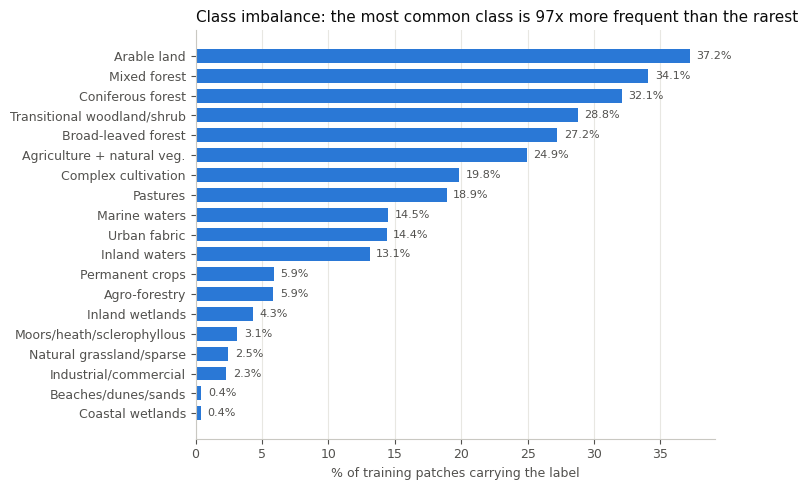

In [13]:
# Class balance and per-channel statistics (from the training split only)
Xtr, Ytr, keep_tr = data["train"]
prevalence = Ytr[keep_tr].mean(0)
sample = np.sort(np.random.default_rng(SEED).choice(keep_tr, size=min(20000, len(keep_tr)), replace=False))
px = np.asarray(Xtr[sample], dtype=np.float32).reshape(-1, 3)
MEAN, STD = px.mean(0), px.std(0)
print("channel mean:", MEAN.round(1), " std:", STD.round(1))

INK, MUTED, BLUE, ORANGE = "#0b0b0b", "#52514e", "#2a78d6", "#eb6834"
def style(ax, xlabel=None, ylabel=None, title=None):
    ax.spines[["top", "right"]].set_visible(False)
    for s in ("left", "bottom"): ax.spines[s].set_color("#c9c8c2")
    ax.tick_params(colors=MUTED, labelsize=9); ax.grid(axis="x" if ylabel is None else "y", color="#e8e7e2", lw=0.8)
    ax.set_axisbelow(True)
    if xlabel: ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    if ylabel: ax.set_ylabel(ylabel, color=MUTED, fontsize=9)
    if title: ax.set_title(title, color=INK, fontsize=11, loc="left")

order = np.argsort(prevalence)
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh([SHORT[i] for i in order], 100 * prevalence[order], color=BLUE, height=0.7)
for y, i in enumerate(order):
    ax.text(100 * prevalence[i] + 0.5, y, f"{100 * prevalence[i]:.1f}%", va="center", fontsize=8, color=MUTED)
style(ax, xlabel="% of training patches carrying the label", title=f"Class imbalance: the most common class is {prevalence.max() / prevalence.min():.0f}x more frequent than the rarest")
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/class_balance.png", dpi=150); plt.show()

## 3. Batching and augmentation
Batches are plain index operations on the `uint8` array — no per-image Python. If the training set fits on the GPU it lives there.

Augmentation is limited to horizontal/vertical flips and 90° rotations. A satellite patch has no canonical orientation, so these never
change which land-cover classes are present. **Random cropping is deliberately absent**: the labels describe the whole 1.2 km × 1.2 km patch.

In [14]:
class ArrayLoader:
    """Yields (uint8 NHWC images, float labels) on `device`. Images and labels are indexed by the same `idx` in the same
    statement, so they cannot get out of step."""
    def __init__(self, split, batch_size, shuffle, on_gpu=False):
        X, Y, keep = data[split]
        self.n, self.bs, self.shuffle, self.on_gpu = len(keep), batch_size, shuffle, on_gpu
        self.Y = torch.from_numpy(Y[keep]).float().to(device)
        if on_gpu:
            self.X = torch.empty((self.n, IMG, IMG, 3), dtype=torch.uint8, device=device)
            for i in range(0, self.n, 8192):
                self.X[i:i + 8192] = torch.from_numpy(np.ascontiguousarray(X[keep[i:i + 8192]]))
        else:
            self.X, self.keep = X, keep
    def __len__(self):
        return math.ceil(self.n / self.bs) if not self.shuffle else self.n // self.bs
    def __iter__(self):
        perm = torch.randperm(self.n) if self.shuffle else torch.arange(self.n)
        for b in range(len(self)):
            idx = perm[b * self.bs:(b + 1) * self.bs]
            if self.on_gpu:
                idx = idx.to(device); x = self.X[idx]
            else:
                idx = idx.sort().values                      # sorted reads are kinder to the memory-mapped file
                x = torch.from_numpy(self.X[self.keep[idx.numpy()]]).to(device, non_blocking=True)
                idx = idx.to(device)
            yield x, self.Y[idx]

_mean = torch.tensor(MEAN, device=device).view(1, 3, 1, 1)
_std = torch.tensor(STD, device=device).view(1, 3, 1, 1)

def prep(x, train):
    x = (x.permute(0, 3, 1, 2).float() - _mean) / _std
    if train:
        b = x.shape[0]
        x = torch.where(torch.rand(b, 1, 1, 1, device=x.device) < 0.5, x.flip(3), x)
        x = torch.where(torch.rand(b, 1, 1, 1, device=x.device) < 0.5, x.flip(2), x)
        x = torch.rot90(x, int(torch.randint(0, 4, ()).item()), dims=(2, 3))
    return x.contiguous(memory_format=torch.channels_last)

train_bytes = len(keep_tr) * IMG * IMG * 3
if DATA_ON_GPU == "auto":
    on_gpu = device.type == "cuda" and torch.cuda.mem_get_info()[0] > train_bytes + 10 * 2**30
else:
    on_gpu = bool(DATA_ON_GPU) and device.type == "cuda"
print("training set on GPU:", on_gpu)
train_loader = ArrayLoader("train", BATCH_SIZE, shuffle=True, on_gpu=on_gpu)
val_loader = ArrayLoader("val", 1024, shuffle=False)
test_loader = ArrayLoader("test", 1024, shuffle=False)

training set on GPU: True


## 4. Model
A from-scratch PyTorch CCT following Hassani et al. (2021): convolutional tokenizer → learnable positional embedding →
pre-norm transformer encoder with stochastic depth → sequence pooling → linear head.

The paper's CIFAR tokenizer (two 3×3 conv + max-pool blocks) turns a 32×32 image into 64 tokens. Applied unchanged to a 120×120 patch it
gives 30×30 = **900 tokens**, and self-attention cost grows with the square of that. One extra conv block gives 15×15 = **225 tokens**
(each token ≈ 80 m × 80 m on the ground), cutting attention cost ~16× — this is the paper's own recipe for larger inputs ("repeatable for further downsampling").

| preset | layers | heads | dim | MLP ratio |
|---|---|---|---|---|
| `cct2` | 2 | 2 | 128 | 1 |
| `cct4` | 4 | 2 | 128 | 1 |
| `cct7` | 7 | 4 | 256 | 2 |

In [15]:
class DropPath(nn.Module):
    def __init__(self, p): super().__init__(); self.p = p
    def forward(self, x):
        if not self.training or self.p == 0: return x
        keep = torch.rand(x.shape[0], 1, 1, device=x.device) >= self.p
        return x * keep / (1 - self.p)

class EncoderLayer(nn.Module):
    def __init__(self, dim, heads, mlp_ratio, drop_path, attn_drop=0.1):
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, dropout=attn_drop, batch_first=True)
        self.mlp = nn.Sequential(nn.Linear(dim, int(dim * mlp_ratio)), nn.GELU(), nn.Linear(int(dim * mlp_ratio), dim))
        self.dp = DropPath(drop_path)
    def forward(self, x):
        h = self.n1(x)
        x = x + self.dp(self.attn(h, h, h, need_weights=False)[0])
        return x + self.dp(self.mlp(self.n2(x)))

class CCT(nn.Module):
    def __init__(self, num_classes, dim, depth, heads, mlp_ratio, n_conv=3, img_size=IMG, drop_path=0.1):
        super().__init__()
        chans = [3] + [64] * (n_conv - 1) + [dim]
        self.tokenizer = nn.Sequential(*[m for i in range(n_conv) for m in (
            nn.Conv2d(chans[i], chans[i + 1], 3, 1, 1, bias=False), nn.ReLU(inplace=True), nn.MaxPool2d(3, 2, 1))])
        with torch.no_grad():
            side = self.tokenizer(torch.zeros(1, 3, img_size, img_size)).shape[-1]
        self.num_tokens = side * side
        self.pos = nn.Parameter(torch.zeros(1, self.num_tokens, dim)); nn.init.trunc_normal_(self.pos, std=0.2)
        rates = torch.linspace(0, drop_path, depth).tolist()
        self.layers = nn.ModuleList([EncoderLayer(dim, heads, mlp_ratio, r) for r in rates])
        self.norm = nn.LayerNorm(dim)
        self.pool = nn.Linear(dim, 1)            # sequence pooling: learned attention weights over tokens
        self.head = nn.Linear(dim, num_classes)
        self.apply(self._init)
    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02); nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight)
    def forward(self, x):
        x = self.tokenizer(x).flatten(2).transpose(1, 2) + self.pos       # (B, tokens, dim)
        for layer in self.layers: x = layer(x)
        x = self.norm(x)
        w = F.softmax(self.pool(x), dim=1)                                 # (B, tokens, 1)
        return self.head((w * x).sum(1))

PRESETS = {"cct2": dict(dim=128, depth=2, heads=2, mlp_ratio=1),
           "cct4": dict(dim=128, depth=4, heads=2, mlp_ratio=1),
           "cct7": dict(dim=256, depth=7, heads=4, mlp_ratio=2)}

def build_model(name):
    if name in PRESETS:
        return CCT(NUM_CLASSES, drop_path=DROP_PATH, **PRESETS[name])
    if name == "resnet18":                       # CNN baseline trained by the identical pipeline
        import torchvision
        m = torchvision.models.resnet18(weights=None, num_classes=NUM_CLASSES)
        m.maxpool = nn.Identity()                # 120 px input: keep more resolution than the ImageNet stem does
        return m
    raise ValueError(name)

model = build_model(MODEL).to(device).to(memory_format=torch.channels_last)
N_PARAMS = sum(p.numel() for p in model.parameters())
print(f"{MODEL}: {N_PARAMS / 1e6:.2f} M parameters" + (f", {model.num_tokens} tokens" if hasattr(model, "num_tokens") else ""))

cct7: 3.94 M parameters, 225 tokens


## 5. Metrics
All computed from the same `(probabilities, labels)` pair.

* **micro precision / recall / F1** — the benchmark paper's headline metrics.
* **micro-Jaccard** = TP / (TP + FP + FN). This is what the benchmark paper's "Accuracy" column is: plugging its published
  precision and recall into P·R / (P + R − P·R) reproduces that column to the decimal for every model I checked.
* **macro-F1** and **mAP** — class-averaged, so the rare classes count as much as the common ones.

In [16]:
from sklearn.metrics import average_precision_score

def confusion(probs, y, thr=0.5):
    pred = probs >= thr
    yb = y.astype(bool)
    return (pred & yb).sum(0), (pred & ~yb).sum(0), (~pred & yb).sum(0)      # per-class TP, FP, FN

def metrics(probs, y, thr=0.5, with_map=True):
    tp, fp, fn = confusion(probs, y, thr)
    P, R = tp.sum() / max(tp.sum() + fp.sum(), 1), tp.sum() / max(tp.sum() + fn.sum(), 1)
    f1_c = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    out = {"micro_precision": P, "micro_recall": R, "micro_f1": 2 * P * R / max(P + R, 1e-12),
           "micro_jaccard": tp.sum() / max(tp.sum() + fp.sum() + fn.sum(), 1), "macro_f1": f1_c.mean()}
    if with_map:
        ok = y.sum(0) > 0
        out["mAP"] = average_precision_score(y[:, ok], probs[:, ok], average="macro")
    return {k: float(v) for k, v in out.items()}

@torch.no_grad()
def predict(model, loader):
    """One ordered pass. Probabilities and labels are collected from the same batches."""
    model.eval(); P, Y = [], []
    for x, y in loader:
        with torch.autocast(device.type, enabled=device.type == "cuda"):
            logits = model(prep(x, train=False))
        P.append(torch.sigmoid(logits.float()).cpu()); Y.append(y.cpu())
    return torch.cat(P).numpy(), torch.cat(Y).numpy().astype(np.uint8)

# unit check on a hand-computable case: TP=2, FP=1, FN=1
_m = metrics(np.array([[.9, .9, .1], [.9, .1, .1]]), np.array([[1, 0, 0], [1, 0, 1]]), with_map=False)
assert abs(_m["micro_precision"] - 2 / 3) < 1e-9 and abs(_m["micro_recall"] - 2 / 3) < 1e-9 and abs(_m["micro_jaccard"] - .5) < 1e-9

## 6. Sanity check before spending GPU hours
A model wired correctly can memorise one small batch. If this loss does not fall well below the "predict the base rate" level, treat the
run with suspicion. Transformers often sit at the base-rate loss for a few dozen steps before breaking through; CNNs drop immediately.

In [17]:
xb, yb = next(iter(ArrayLoader("train", 32, shuffle=False)))
probe = build_model(MODEL).to(device)
opt = torch.optim.AdamW(probe.parameters(), lr=3e-4)
probe.train()
base = F.binary_cross_entropy(yb.mean(0, keepdim=True).expand_as(yb).clamp(1e-4, 1 - 1e-4), yb).item()
for step in range(400 if device.type == "cuda" else int(os.environ.get("BEN_PROBE_STEPS", 40))):
    loss = F.binary_cross_entropy_with_logits(probe(prep(xb, train=False)), yb)
    opt.zero_grad(); loss.backward(); opt.step()
print(f"base-rate loss {base:.3f} -> after memorising one batch {loss.item():.3f}")
if loss.item() > 0.75 * base:
    print("WARNING: the model did not memorise a single batch. Check the model / data wiring before trusting a long run.")
del probe, opt

base-rate loss 0.087 -> after memorising one batch 0.003


## 7. Training
AdamW, linear warm-up then cosine decay, mixed precision, gradient clipping, plain binary cross-entropy (no label smoothing).
The checkpoint kept as "best" is chosen by **validation micro-F1**. The cell is resumable: if Colab disconnects, re-run the notebook and it
continues from the last finished epoch.

In [18]:
decay = [p for n, p in model.named_parameters() if p.ndim > 1 and n != "pos"]
no_decay = [p for n, p in model.named_parameters() if p.ndim <= 1 or n == "pos"]
optimizer = torch.optim.AdamW([{"params": decay, "weight_decay": WEIGHT_DECAY},
                               {"params": no_decay, "weight_decay": 0.0}], lr=PEAK_LR)
scaler = torch.amp.GradScaler(enabled=device.type == "cuda")
steps_per_epoch = len(train_loader)
total_steps, warmup_steps = EPOCHS * steps_per_epoch, WARMUP_EPOCHS * steps_per_epoch

def lr_at(step):
    if step < warmup_steps:
        return PEAK_LR * (step + 1) / warmup_steps
    t = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return PEAK_LR * 0.5 * (1 + math.cos(math.pi * min(t, 1.0)))

LAST, BEST = f"{RUN_DIR}/last.pt", f"{RUN_DIR}/best.pt"
history, best_f1, start_epoch = [], -1.0, 0
if os.path.exists(LAST):
    ck = torch.load(LAST, map_location=device)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"]); scaler.load_state_dict(ck["scaler"])
    history, best_f1, start_epoch = ck["history"], ck["best_f1"], ck["epoch"] + 1
    print(f"Resumed from {LAST}: {start_epoch} epoch(s) already done, best val micro-F1 {best_f1:.4f}")

for epoch in range(start_epoch, EPOCHS):
    model.train(); t0 = time.time(); running, seen = 0.0, 0
    for i, (x, y) in enumerate(train_loader):
        step = epoch * steps_per_epoch + i
        for g in optimizer.param_groups: g["lr"] = lr_at(step)
        with torch.autocast(device.type, enabled=device.type == "cuda"):
            logits = model(prep(x, train=True))
        loss = F.binary_cross_entropy_with_logits(logits.float(), y)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update()
        running += loss.item() * len(y); seen += len(y)
        if epoch == start_epoch and i == 50:
            rate = seen / (time.time() - t0)
            print(f"  throughput ~{rate:,.0f} img/s -> ~{train_loader.n / rate / 60:.1f} min per training epoch, "
                  f"~{(EPOCHS - epoch) * train_loader.n / rate / 3600:.1f} h of training left (plus validation)")
    probs, yv = predict(model, val_loader)
    m = metrics(probs, yv, with_map=False)
    row = {"epoch": epoch + 1, "train_loss": running / seen, "seconds": time.time() - t0,
           "val_loss": float(F.binary_cross_entropy(torch.from_numpy(probs).clamp(1e-6, 1 - 1e-6), torch.from_numpy(yv).float())),
           **{f"val_{k}": v for k, v in m.items()}}
    history.append(row)
    print(f"epoch {epoch + 1:2d}/{EPOCHS}  train loss {row['train_loss']:.4f}  val loss {row['val_loss']:.4f}  "
          f"val micro-F1 {m['micro_f1']:.4f}  P {m['micro_precision']:.3f}  R {m['micro_recall']:.3f}  "
          f"macro-F1 {m['macro_f1']:.4f}  ({row['seconds'] / 60:.1f} min)")
    if m["micro_f1"] > best_f1:
        best_f1 = m["micro_f1"]; torch.save({"model": model.state_dict(), "epoch": epoch}, BEST)
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scaler": scaler.state_dict(),
                "history": history, "best_f1": best_f1, "epoch": epoch}, LAST)
    json.dump(history, open(f"{RUN_DIR}/history.json", "w"), indent=1)

  throughput ~1,707 img/s -> ~2.6 min per training epoch, ~1.3 h of training left (plus validation)
epoch  1/30  train loss 0.2996  val loss 0.2141  val micro-F1 0.6521  P 0.766  R 0.568  macro-F1 0.4497  (1.4 min)
epoch  2/30  train loss 0.2068  val loss 0.1930  val micro-F1 0.6974  P 0.771  R 0.637  macro-F1 0.5355  (1.3 min)
epoch  3/30  train loss 0.1893  val loss 0.1795  val micro-F1 0.7215  P 0.791  R 0.663  macro-F1 0.5836  (1.3 min)
epoch  4/30  train loss 0.1785  val loss 0.1727  val micro-F1 0.7285  P 0.814  R 0.660  macro-F1 0.5954  (1.3 min)
epoch  5/30  train loss 0.1711  val loss 0.1661  val micro-F1 0.7474  P 0.805  R 0.697  macro-F1 0.6268  (1.3 min)
epoch  6/30  train loss 0.1658  val loss 0.1652  val micro-F1 0.7566  P 0.778  R 0.737  macro-F1 0.6666  (1.3 min)
epoch  7/30  train loss 0.1612  val loss 0.1595  val micro-F1 0.7613  P 0.803  R 0.724  macro-F1 0.6627  (1.3 min)
epoch  8/30  train loss 0.1571  val loss 0.1597  val micro-F1 0.7570  P 0.813  R 0.708  macro-F

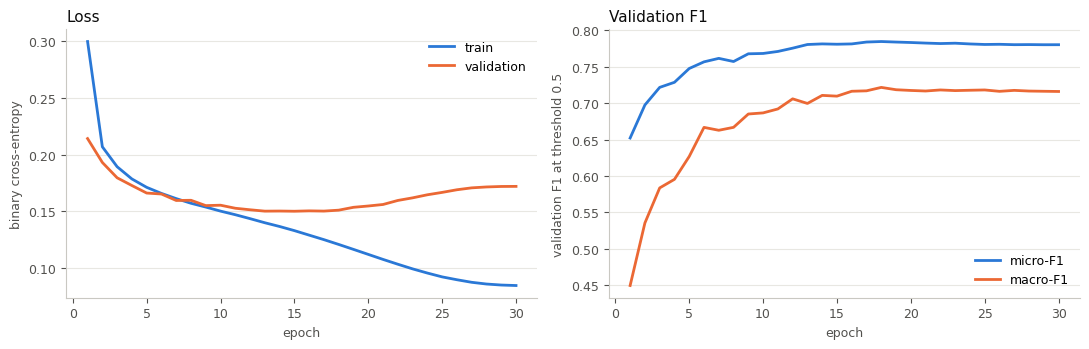

In [19]:
ep = [h["epoch"] for h in history]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(ep, [h["train_loss"] for h in history], color=BLUE, lw=2, label="train")
axes[0].plot(ep, [h["val_loss"] for h in history], color=ORANGE, lw=2, label="validation")
style(axes[0], xlabel="epoch", ylabel="binary cross-entropy", title="Loss"); axes[0].legend(frameon=False, fontsize=9)
axes[1].plot(ep, [h["val_micro_f1"] for h in history], color=BLUE, lw=2, label="micro-F1")
axes[1].plot(ep, [h["val_macro_f1"] for h in history], color=ORANGE, lw=2, label="macro-F1")
style(axes[1], xlabel="epoch", ylabel="validation F1 at threshold 0.5", title="Validation F1"); axes[1].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/curves.png", dpi=150); plt.show()

## 8. Test-set evaluation
The best checkpoint (by validation micro-F1) is reloaded and the test split is scored once.
The headline numbers use a fixed 0.5 threshold, as the benchmark does. A second row uses per-class thresholds tuned on the **validation**
split and then applied unchanged to test — a standard, leak-free way to help the rare classes.

                                     micro_precision  micro_recall  micro_f1  \
threshold 0.5                                 0.8082        0.7610    0.7839   
per-class thresholds (tuned on val)           0.7586        0.8179    0.7871   

                                     micro_jaccard  macro_f1     mAP  
threshold 0.5                               0.6446    0.7242  0.7954  
per-class thresholds (tuned on val)         0.6490    0.7315  0.7954  
                      class  test support  prevalence  precision  recall  F1 @0.5  F1 tuned  tuned threshold    AP
               Urban fabric         17928       0.142      0.813   0.754    0.782     0.784             0.40 0.875
      Industrial/commercial          2808       0.022      0.659   0.452    0.536     0.562             0.35 0.573
                Arable land         47150       0.375      0.867   0.851    0.859     0.861             0.40 0.943
            Permanent crops          6812       0.054      0.700   0.582    0.636     

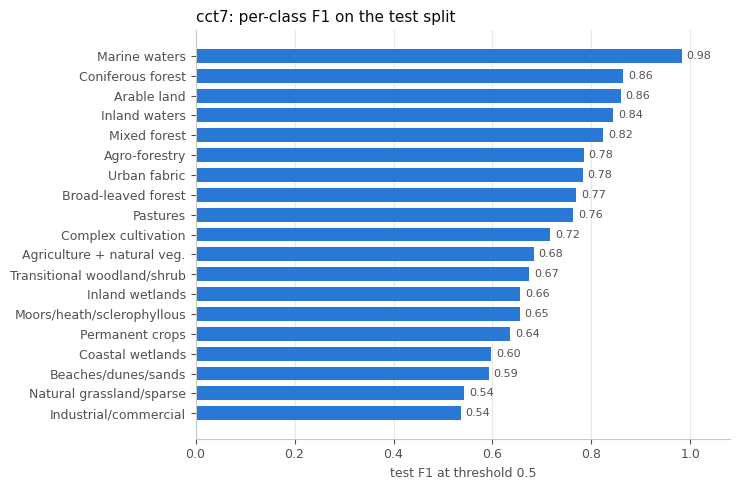

In [20]:
model.load_state_dict(torch.load(BEST, map_location=device)["model"])
val_probs, val_y = predict(model, val_loader)
test_probs, test_y = predict(model, test_loader)
assert test_probs.shape == test_y.shape == (test_loader.n, NUM_CLASSES)

grid = np.arange(0.05, 0.96, 0.05)
def f1_per_class(probs, y, thr):
    tp, fp, fn = confusion(probs, y, thr); return 2 * tp / np.maximum(2 * tp + fp + fn, 1)
tuned_thr = grid[np.stack([f1_per_class(val_probs, val_y, t) for t in grid]).argmax(0)]

test_05 = metrics(test_probs, test_y, 0.5)
test_tuned = metrics(test_probs, test_y, tuned_thr)

import pandas as pd
summary = pd.DataFrame({"threshold 0.5": test_05, "per-class thresholds (tuned on val)": test_tuned}).T
display(summary.style.format("{:.4f}")) if "display" in globals() else print(summary.round(4))

tp, fp, fn = confusion(test_probs, test_y, 0.5)
per_class = pd.DataFrame({
    "class": SHORT, "test support": test_y.sum(0), "prevalence": test_y.mean(0),
    "precision": tp / np.maximum(tp + fp, 1), "recall": tp / np.maximum(tp + fn, 1),
    "F1 @0.5": f1_per_class(test_probs, test_y, 0.5), "F1 tuned": f1_per_class(test_probs, test_y, tuned_thr),
    "tuned threshold": tuned_thr,
    "AP": [average_precision_score(test_y[:, c], test_probs[:, c]) if test_y[:, c].any() else np.nan for c in range(NUM_CLASSES)],
})
per_class.to_csv(f"{RUN_DIR}/per_class.csv", index=False)
print(per_class.round(3).to_string(index=False))

order = np.argsort(per_class["F1 @0.5"].values)
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh([SHORT[i] for i in order], per_class["F1 @0.5"].values[order], color=BLUE, height=0.7)
for yy, i in enumerate(order):
    ax.text(per_class["F1 @0.5"].values[i] + 0.01, yy, f"{per_class['F1 @0.5'].values[i]:.2f}", va="center", fontsize=8, color=MUTED)
ax.set_xlim(0, 1.08)
style(ax, xlabel="test F1 at threshold 0.5", title=f"{MODEL}: per-class F1 on the test split")
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/per_class_f1.png", dpi=150); plt.show()

results = {"model": MODEL, "params_M": N_PARAMS / 1e6, "epochs_trained": len(history),
           "train_minutes": sum(h["seconds"] for h in history) / 60, "data_source": DATA_SOURCE,
           "test@0.5": test_05, "test@tuned": test_tuned}
json.dump(results, open(f"{RUN_DIR}/results.json", "w"), indent=1)

## 9. Reproducing the original evaluation bug
The 2024 notebook shuffled the test set before `model.predict`, then compared the output with labels in their original order. The cell below
does the same thing on purpose to the *good* model above. Two things should happen:

* micro-F1 collapses to roughly the range the capstone reported;
* each class's precision becomes equal to how common the class is — exactly the pattern in the old notebook's per-class precision table.

In [21]:
perm = np.random.default_rng(SEED).permutation(len(test_y))
bug = metrics(test_probs[perm], test_y, 0.5, with_map=False)
tp_b, fp_b, _ = confusion(test_probs[perm], test_y, 0.5)
has_pred = (tp_b + fp_b) >= 50                     # precision is only meaningful for classes the model predicts
prec_b = tp_b[has_pred] / (tp_b + fp_b)[has_pred]
print(f"aligned  : micro-F1 {test_05['micro_f1']:.3f}  precision {test_05['micro_precision']:.3f}  recall {test_05['micro_recall']:.3f}")
print(f"shuffled : micro-F1 {bug['micro_f1']:.3f}  precision {bug['micro_precision']:.3f}  recall {bug['micro_recall']:.3f}")
if has_pred.sum() >= 3:
    print(f"correlation between shuffled per-class precision and class prevalence: "
          f"{np.corrcoef(prec_b, test_y.mean(0)[has_pred])[0, 1]:.3f}  (the 2024 notebook's table: 0.999)")
results["shuffled_label_control"] = bug
json.dump(results, open(f"{RUN_DIR}/results.json", "w"), indent=1)

aligned  : micro-F1 0.784  precision 0.808  recall 0.761
shuffled : micro-F1 0.245  precision 0.253  recall 0.238
correlation between shuffled per-class precision and class prevalence: 1.000  (the 2024 notebook's table: 0.999)


## 10. Comparison
Every run found under `OUT_ROOT` is listed with a few rows from Papoutsis et al. (2023), Table 2 of the capstone.

**Read the comparison with these caveats** — they belong in any write-up:

* The benchmark models were trained on ~10 Sentinel-2 spectral bands; this notebook uses the 3-band RGB rendering. Near-infrared and
  short-wave infrared carry much of the signal for vegetation and water classes, so RGB-only models are at a disadvantage.
* The benchmark uses the full 590k-patch archive; this Hugging Face copy is the 519k-patch version with snow/cloud patches removed.
* The `resnet18` preset is trained by this exact pipeline on this exact data, so **CCT vs. that baseline is the like-for-like comparison**.

In [22]:
rows = []
for path in sorted(glob.glob(f"{OUT_ROOT}/*/results.json")):
    r = json.load(open(path)); t = r["test@0.5"]
    rows.append({"model": f"{r['model']} (this work, RGB)", "params (M)": round(r["params_M"], 2),
                 "micro-Jaccard ('accuracy')": 100 * t["micro_jaccard"], "precision": 100 * t["micro_precision"],
                 "recall": 100 * t["micro_recall"], "micro-F1": 100 * t["micro_f1"], "macro-F1": 100 * t["macro_f1"],
                 "epochs": r["epochs_trained"], "train min": round(r["train_minutes"], 1)})
for name, params, acc, p, rcl, f1 in [("ResNet50 (Papoutsis et al., ~10 bands)", 23, 62.4, 78.8, 75.0, 76.8),
                                      ("VGG19 (Papoutsis et al.)", 20, 63.6, 81.7, 74.2, 77.7),
                                      ("ViT/20 (Papoutsis et al.)", 7, 62.1, 80.5, 73.1, 76.6),
                                      ("WRN-B0-ECA (Papoutsis et al.)", 0.3, 61.7, 81.5, 71.8, 76.3),
                                      ("MLPMixerTiny (Papoutsis et al.)", 0.04, 55.7, 77.5, 66.5, 71.6),
                                      ("K-Branch CNN (Papoutsis et al.)", 36, 47.3, 63.4, 65.1, 64.2)]:
    rows.append({"model": name, "params (M)": params, "micro-Jaccard ('accuracy')": acc, "precision": p, "recall": rcl, "micro-F1": f1})
rows.append({"model": "CCT-2, 2024 capstone (mis-scored)", "params (M)": 0.4, "precision": 25.12, "recall": 13.52, "micro-F1": 17.58})
table = pd.DataFrame(rows)
table.to_csv(f"{OUT_ROOT}/comparison.csv", index=False)
print(table.round({c: 1 for c in table.columns if c != "params (M)"}).to_string(index=False, na_rep="-"))

                                 model  params (M)  micro-Jaccard ('accuracy')  precision  recall  micro-F1  macro-F1  epochs  train min
                 cct7 (this work, RGB)        3.94                        64.5       80.8    76.1      78.4      72.4    30.0       38.5
ResNet50 (Papoutsis et al., ~10 bands)       23.00                        62.4       78.8    75.0      76.8         -       -          -
              VGG19 (Papoutsis et al.)       20.00                        63.6       81.7    74.2      77.7         -       -          -
             ViT/20 (Papoutsis et al.)        7.00                        62.1       80.5    73.1      76.6         -       -          -
         WRN-B0-ECA (Papoutsis et al.)        0.30                        61.7       81.5    71.8      76.3         -       -          -
       MLPMixerTiny (Papoutsis et al.)        0.04                        55.7       77.5    66.5      71.6         -       -          -
       K-Branch CNN (Papoutsis et al.)   